# **Model Selection**

**Author:** Keith Megara Osores Vicuña  
  
**Master:** Health Data Science

**Subject:** Scientific Programming

**Course:** 2025-2026

---

## **Table of Contents**

**1. [Initial setups and definitions](#section1)**   
&emsp; **1.1 [Setup](#section11)**  
&emsp; **1.2 [Paths and seeds](#section12)**  
&emsp; **1.3 [Feature and target definition](#section13)**  

**2. [Model Plan](#section2)**   

**3. [Data Loading and Models execution](#section3)**   

**4. [Model Selection](#section4)**   
&emsp; **4.1 [Comparison tables: Traditional models](#section41)**  
&emsp; **4.2 [Comparison tables: Boosting and stacked ensembles](#section42)**  
&emsp; **4.3 [Comparison between traditional models and boosting/stacked ensemble models](#section43)**   
&emsp; **4.4 [Learning and validation curves](#section44)**   
&emsp; **4.5 [Feature importance fo best model](#section45)**   
&emsp; **4.6 [SHAP Analysis of best model](#section46)**   

 
---

<a id='section1'></a>
# 1. Initial setups and definitions

<a id='section11'></a>
## 1.1 Setup

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import learning_curve, validation_curve

import shap
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
    
from src.models.traditional_ml import (load_dataset, prepare_features)
from src.models.ensemble_models import (main)

<a id='section12'></a>
## 1.2 Paths and seeds

In [2]:
# SETTINGS
MODELS_DIR = '../models'
DATA_DIR = '../data/processed'
SAVE_DIR = '../figures/03_Model_Selection'

os.makedirs(SAVE_DIR, exist_ok=True)

<a id='section13'></a>
## 1.3 Feature and target definition

In [3]:
TARGET = 'TenYearCHD'
FEATURES = [
    'bmi',
    'hypertension',
    'pulse_pressure',
    'cigarettes_per_day',
    'total_cholesterol',
    'glucose',
    'heart_rate',
    'age_group_code',
]

<a id='section2'></a>
# 2. Model Plan:

Implement ensemble methods:
- Gradient Boosting (XGBoost, LightGBM)
- AdaBoost
- 2 Stacking ensembles

Tune hyperparameters (via Optuna)
Select the best model from this part based on:
- ROC-AUC score
- Recall (important for medical diagnosis)
- Model interpretability
- Inference speed

Compare results with best traditional model

Select the best model among all of them.

Generate for the best model:
- Learning curves
- Validation curves
- Feature importance analysis
- Generate SHAP explanations for model interpretability
- Save final model (best results)

<a id='section3'></a>
# 3. Data Loading and Models execution:

In [4]:
DATASET_VERSIONS = ["unscaled", "standard_scaled", "robust_scaled"]

all_results = {}

for scaling_type in DATASET_VERSIONS:
    print("\n" + "=" * 100)
    print(f" RUNNING PIPELINE FOR DATASET VERSION: {scaling_type.upper()}")
    print("=" * 100)

    train_fp = os.path.join(DATA_DIR, f"train_{scaling_type}.csv")
    test_fp = os.path.join(DATA_DIR, f"test_{scaling_type}.csv")

    results = main(
        train_filepath=train_fp,
        test_filepath=test_fp,
        target_col_name=TARGET,
        scaling_type=scaling_type
    )

    all_results[scaling_type] = results

[I 2026-01-15 19:18:06,634] A new study created in memory with name: no-name-4d8edc02-eac1-41fd-9d36-98556bcb3566



 RUNNING PIPELINE FOR DATASET VERSION: UNSCALED
CORONARY HEART DISEASE PREDICTION PROJECT
Advanced Models & Model Selection per dataset version.
Traditional Models not considered. They will be incorporated in the following part of this notebook.
    Start Time: 2026-01-15 19:18:06
LOADING PRESPLIT DATA

Loading training data from: ../data/processed\train_unscaled.csv
  Shape: (3390, 9)

Loading test data from: ../data/processed\test_unscaled.csv
  Shape: (848, 9)

Target column: TenYearCHD

Data split information:
  - Training set: (3390, 8)
  - Test set: (848, 8)

Feature consistency verified

Training Set Class Distribution:
  - Class 0 (No CHD): 2875 (84.81%)
  - Class 1 (CHD): 515 (15.19%)
  - Imbalance Ratio: 5.58:1

Test Set Class Distribution:
  - Class 0 (No CHD): 719 (84.79%)
  - Class 1 (CHD): 129 (15.21%)
  - Imbalance Ratio: 5.57:1

 - No categorical variables found (all numeric)

 - Features (8):
   1. bmi
   2. hypertension
   3. pulse_pressure
   4. cigarettes_per_day
 

[I 2026-01-15 19:18:08,110] Trial 0 finished with value: 0.44172404671450693 and parameters: {'n_estimators': 350, 'max_depth': 6, 'learning_rate': 0.07587945476302646, 'subsample': 0.8197316968394073, 'colsample_bytree': 0.7312037280884873, 'min_child_weight': 2, 'gamma': 0.2904180608409973, 'reg_alpha': 4.330880728874676, 'reg_lambda': 3.20501755284444}. Best is trial 0 with value: 0.44172404671450693.
[I 2026-01-15 19:18:09,254] Trial 1 finished with value: 0.446395722527086 and parameters: {'n_estimators': 483, 'max_depth': 3, 'learning_rate': 0.0972918866945795, 'subsample': 0.8664885281600844, 'colsample_bytree': 0.7424678221356552, 'min_child_weight': 2, 'gamma': 0.9170225492671691, 'reg_alpha': 1.5212112147976886, 'reg_lambda': 2.86140394234507}. Best is trial 1 with value: 0.446395722527086.
[I 2026-01-15 19:18:10,080] Trial 2 finished with value: 0.4417447586886168 and parameters: {'n_estimators': 373, 'max_depth': 4, 'learning_rate': 0.06506676052501416, 'subsample': 0.72789


Optimization completed.
  - Best ROC-AUC: 0.4506
  - Best parameters:
    n_estimators: 583
    max_depth: 3
    learning_rate: 0.09551409000498795
    subsample: 0.8797047767216731
    colsample_bytree: 0.819642101133928
    min_child_weight: 8
    gamma: 0.5732522977673149
    reg_alpha: 2.743326150768452
    reg_lambda: 1.1699277532090642
HYPERPARAMETER TUNING - LightGBM

Calculated scale_pos_weight: 5.58

Starting Optuna optimization (50 trials)...
  Objective: 0.6*ROC-AUC + 0.4*Recall
[LightGBM] [Warning] min_data_in_leaf is set=32, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=32
[LightGBM] [Warning] lambda_l1 is set=0.2904180608409973, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.2904180608409973
[LightGBM] [Warning] lambda_l2 is set=4.330880728874676, reg_lambda=0.0 will be ignored. Current value: lambda_l2=4.330880728874676
[LightGBM] [Warning] min_data_in_leaf is set=32, min_child_samples=20 will be ignored. Current value: min_data_in_lea

[I 2026-01-15 19:19:11,109] Trial 0 finished with value: 0.4378677923174336 and parameters: {'n_estimators': 425, 'num_leaves': 77, 'learning_rate': 0.14907884894416698, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.40921304830970556, 'min_data_in_leaf': 32, 'lambda_l1': 0.2904180608409973, 'lambda_l2': 4.330880728874676}. Best is trial 0 with value: 0.4378677923174336.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

... (116 outputs left out)

  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-01-15 19:31:11,662] Trial 0 finished with value: 0.7106171380329254 and parameters: {'n_estimators': 181, 'learning_rate': 0.951207163345817}. Best is trial 0 with value: 0.7106171380329254.
[I 2026-01-15 19:31:14,126] Trial 1 finished with value: 0.7139535669058674 and parameters: {'n_estimators': 306, 'learning_rate': 0.6026718993550663}. Best is trial 1 with value: 0.7139535669058674.
[I 2026-01-15 19:31:14,863] Trial 2 finished with value: 0.7127412410299704 and parameters: {'n_estimators': 104, 'learning_rate': 0.16443457513284063}. Best is trial 1 with value: 0.7139535669058674.
[I 2026-01-15 19:31:15,381] Trial 3 finished with value: 0.7081992401857323 and parameters: {'n_estimators': 70, 'learning_rate': 0.8675143843171859}. Best is trial 1 with value: 0.7139535669058674.
[I 2026-01-15 19:31:17,154] Trial 4 finished with value: 0.7106542845082313 and parameters: {'n_estimators': 260, 'learning_rate': 0.710991852018085}. Best is trial 1 with value: 0.7139535669058674.
[I

  0%|          | 0/50 [00:00<?, ?it/s]

✓ SHAP values shape: (50, 8)
✓ SHAP summary plot saved: shap_summary_adaboost_robust_scaled.png

Top 10 Features by SHAP Importance:
   1. age_group_code                : 0.0551
   2. cigarettes_per_day            : 0.0336
   3. pulse_pressure                : 0.0220
   4. hypertension                  : 0.0145
   5. bmi                           : 0.0098
   6. total_cholesterol             : 0.0021
   7. heart_rate                    : 0.0000
   8. glucose                       : 0.0000
SAVING FINAL MODEL

Model saved: ../models\best_model_robust_scaled.pkl
Metadata saved: ../models\model_metadata_robust_scaled.json

All artifacts saved to: ../models/

DETAILED RESULTS SUMMARY (All Models)

MODEL: XGBoost

Threshold: 0.5251

Test Set Performance (Threshold-Optimized):
  Accuracy:  0.7146
  Precision: 0.2189
  Recall:    0.3411
  F1-Score:  0.2667
  ROC-AUC:   0.6008

Inference Performance:
  Total time: 0.0012 seconds
  Per sample: 0.00 ms

Cross-Validation:
  ROC-AUC: 0.6659 ± 0.0175

<a id='section4'></a>
# 4. Model Selection

<a id='section41'></a>
## 4.1 Comparison tables: Traditional models

In [5]:
comparison_traditional = 'model_comparison.csv'
traditional_comparison_df = pd.read_csv(os.path.join(DATA_DIR, comparison_traditional))

display(traditional_comparison_df.sort_values("test_roc_auc", ascending=False).head(5))

,dataset_version,model_name,imbalance_method,best_params,cv_best_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,standard_scaled,svm,class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.721043,0.669811,0.252459,0.596899,0.354839,0.689712
1,unscaled,svm,class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.721074,0.668632,0.251634,0.596899,0.354023,0.689712
2,robust_scaled,svm,class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.720986,0.668632,0.251634,0.596899,0.354023,0.689588
7,robust_scaled,svm,smote,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.720929,0.650943,0.244648,0.620155,0.350877,0.688887
8,robust_scaled,svm,smote+class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.720929,0.650943,0.244648,0.620155,0.350877,0.688887


In [6]:
traditional_comparison_df = traditional_comparison_df.rename(
    columns={
        "model_name": "model",
        "test_accuracy": "accuracy",
        "test_precision": "precision",
        "test_recall": "recall",
        "test_f1": "f1-score",
        "test_roc_auc": "ROC-AUC"
    }
)

display(traditional_comparison_df.head(5))

,dataset_version,model,imbalance_method,best_params,cv_best_roc_auc,accuracy,precision,recall,f1-score,ROC-AUC
0,standard_scaled,svm,class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.721043,0.669811,0.252459,0.596899,0.354839,0.689712
1,unscaled,svm,class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.721074,0.668632,0.251634,0.596899,0.354023,0.689712
2,robust_scaled,svm,class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.720986,0.668632,0.251634,0.596899,0.354023,0.689588
3,unscaled,svm,smote,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.721145,0.650943,0.244648,0.620155,0.350877,0.687615
4,unscaled,svm,smote+class_weight,"{""model__C"": 5, ""model__gamma"": ""scale"", ""mode...",0.721145,0.650943,0.244648,0.620155,0.350877,0.687615


<a id='section42'></a>
## 4.2 Comparison tables: Boosting and stacked ensembles

In [7]:
unscaled_comparison = all_results['unscaled']['comparison_df']

standard_scaled_comparison = all_results['standard_scaled']['comparison_df']

robust_scaled_comparison = all_results['robust_scaled']['comparison_df']

comparison_boosting_stacked = pd.concat([unscaled_comparison, standard_scaled_comparison, robust_scaled_comparison], ignore_index=True)
display(comparison_boosting_stacked.sort_values("ROC-AUC", ascending=False).reset_index(drop=True).head(10))

print("Best Traditional model: SVM")
print("   Dataset version: unscaled")
print(f"Best unscaled model: {all_results['unscaled']['best_model_name']}")
print(f"Best standard scaled model: {all_results['standard_scaled']['best_model_name']}")
print(f"Best robust scaled model: {all_results['robust_scaled']['best_model_name']}")

,dataset_version,model,imbalance_method,accuracy,precision,recall,f1-score,pr_auc,threshold,inference_time,inference_time_per_sample,ROC-AUC
0,robust_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.600236,0.234848,0.720930,0.354286,0.280405,0.466404,0.133637,0.000158,0.683227
1,standard_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.604953,0.235897,0.713178,0.354528,0.280614,0.469473,0.131044,0.000155,0.683173
2,unscaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.291584,0.436580,0.038810,0.000046,0.677950
3,robust_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.291584,0.436580,0.027501,0.000032,0.677950
4,standard_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.291584,0.436580,0.027766,0.000033,0.677950
5,robust_scaled,Stacking_SVM,"class_weight (RF, SVM, meta-learner)",0.588443,0.229064,0.720930,0.347664,0.274428,0.469405,0.159049,0.000188,0.672995
6,standard_scaled,Stacking_SVM,"class_weight (RF, SVM, meta-learner)",0.668632,0.237931,0.534884,0.329356,0.272637,0.533867,0.161056,0.000190,0.671917
7,robust_scaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.227246,0.525122,0.001202,0.000001,0.600845
8,unscaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.227246,0.525122,0.001159,0.000001,0.600845
9,standard_scaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.227246,0.525122,0.001084,0.000001,0.600845


Best Traditional model: SVM
   Dataset version: unscaled
Best unscaled model: AdaBoost
Best standard scaled model: AdaBoost
Best robust scaled model: AdaBoost


In [8]:
display(comparison_boosting_stacked.sort_values("ROC-AUC", ascending=False).reset_index(drop=True).head(10))

,dataset_version,model,imbalance_method,accuracy,precision,recall,f1-score,pr_auc,threshold,inference_time,inference_time_per_sample,ROC-AUC
0,robust_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.600236,0.234848,0.720930,0.354286,0.280405,0.466404,0.133637,0.000158,0.683227
1,standard_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.604953,0.235897,0.713178,0.354528,0.280614,0.469473,0.131044,0.000155,0.683173
2,unscaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.291584,0.436580,0.038810,0.000046,0.677950
3,robust_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.291584,0.436580,0.027501,0.000032,0.677950
4,standard_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.291584,0.436580,0.027766,0.000033,0.677950
5,robust_scaled,Stacking_SVM,"class_weight (RF, SVM, meta-learner)",0.588443,0.229064,0.720930,0.347664,0.274428,0.469405,0.159049,0.000188,0.672995
6,standard_scaled,Stacking_SVM,"class_weight (RF, SVM, meta-learner)",0.668632,0.237931,0.534884,0.329356,0.272637,0.533867,0.161056,0.000190,0.671917
7,robust_scaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.227246,0.525122,0.001202,0.000001,0.600845
8,unscaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.227246,0.525122,0.001159,0.000001,0.600845
9,standard_scaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.227246,0.525122,0.001084,0.000001,0.600845


<a id='section43'></a>
## 4.3 Comparison between traditional models and boosting/stacked ensemble models:

In [9]:
traditional_relevant = traditional_comparison_df[["dataset_version", "model", "imbalance_method", "accuracy", "precision", "recall", "f1-score", "ROC-AUC"]]
boosting_stacked_relevant = comparison_boosting_stacked[["dataset_version", "model", "imbalance_method", "accuracy", "precision", "recall", "f1-score", "ROC-AUC"]]

comparison_models = pd.concat([traditional_relevant, boosting_stacked_relevant], ignore_index=True)
display(comparison_models.sort_values("ROC-AUC", ascending=False).reset_index(drop=True).head(30))

,dataset_version,model,imbalance_method,accuracy,precision,recall,f1-score,ROC-AUC
0,standard_scaled,svm,class_weight,0.669811,0.252459,0.596899,0.354839,0.689712
1,unscaled,svm,class_weight,0.668632,0.251634,0.596899,0.354023,0.689712
2,robust_scaled,svm,class_weight,0.668632,0.251634,0.596899,0.354023,0.689588
3,robust_scaled,svm,smote+class_weight,0.650943,0.244648,0.620155,0.350877,0.688887
4,robust_scaled,svm,smote,0.650943,0.244648,0.620155,0.350877,0.688887
5,standard_scaled,svm,smote+class_weight,0.650943,0.244648,0.620155,0.350877,0.687637
6,standard_scaled,svm,smote,0.650943,0.244648,0.620155,0.350877,0.687637
7,unscaled,svm,smote,0.650943,0.244648,0.620155,0.350877,0.687615
8,unscaled,svm,smote+class_weight,0.650943,0.244648,0.620155,0.350877,0.687615
9,robust_scaled,logistic_regression,none,0.846698,0.454545,0.038760,0.071429,0.687141


In [10]:
display(comparison_models.tail(10))

,dataset_version,model,imbalance_method,accuracy,precision,recall,f1-score,ROC-AUC
57,standard_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.604953,0.235897,0.713178,0.354528,0.683173
58,standard_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.677950
59,standard_scaled,Stacking_SVM,"class_weight (RF, SVM, meta-learner)",0.668632,0.237931,0.534884,0.329356,0.671917
60,standard_scaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.600845
61,standard_scaled,LightGBM,class_weight,0.793632,0.238636,0.162791,0.193548,0.593212
62,robust_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.600236,0.234848,0.720930,0.354286,0.683227
63,robust_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.677950
64,robust_scaled,Stacking_SVM,"class_weight (RF, SVM, meta-learner)",0.588443,0.229064,0.720930,0.347664,0.672995
65,robust_scaled,XGBoost,scale_pos_weight,0.714623,0.218905,0.341085,0.266667,0.600845
66,robust_scaled,LightGBM,class_weight,0.832547,0.240000,0.046512,0.077922,0.589201


In [11]:
comparison_models['weighted_score'] = 0.6 * comparison_models['ROC-AUC'] + 0.4 * comparison_models['recall']
display(comparison_models.sort_values("weighted_score", ascending=False).reset_index(drop=True).head(10))

,dataset_version,model,imbalance_method,accuracy,precision,recall,f1-score,ROC-AUC,weighted_score
0,standard_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.677950,0.726150
1,unscaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.677950,0.726150
2,robust_scaled,AdaBoost,sample_weight,0.492925,0.203156,0.798450,0.323899,0.677950,0.726150
3,robust_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.600236,0.234848,0.720930,0.354286,0.683227,0.698308
4,standard_scaled,Stacking_ET,"class_weight (RF, SVM, meta-learner)",0.604953,0.235897,0.713178,0.354528,0.683173,0.695175
5,robust_scaled,Stacking_SVM,"class_weight (RF, SVM, meta-learner)",0.588443,0.229064,0.720930,0.347664,0.672995,0.692169
6,robust_scaled,svm,smote+class_weight,0.650943,0.244648,0.620155,0.350877,0.688887,0.661394
7,robust_scaled,svm,smote,0.650943,0.244648,0.620155,0.350877,0.688887,0.661394
8,standard_scaled,svm,smote+class_weight,0.650943,0.244648,0.620155,0.350877,0.687637,0.660644
9,standard_scaled,svm,smote,0.650943,0.244648,0.620155,0.350877,0.687637,0.660644


Since SMOTE can introduce biological implausible samples, we cannot consider those models using it. Therefore, the best model based on ROC-AUC, f1-score and weighted score (considering recall) is SVM model with class_weight as imbalance method and using standard scaled dataset version.

In [12]:
best_model_parameters = traditional_comparison_df.iloc[0,3]
print(best_model_parameters)

{"model__C": 5, "model__gamma": "scale", "model__kernel": "linear"}


<a id='section44'></a>
## 4.4 Learning and validation curves

In [13]:
# Load best model
best_model_name = 'best_model__standard_scaled__svm__class_weight.pkl'
best_model_dataset_version = 'test_standard_scaled.csv'

best_model_path = os.path.join(MODELS_DIR, best_model_name)
with open(best_model_path, 'rb') as file:
    model_fitted_pipeline = joblib.load(file)
    
print("Loaded fitted pipeline:")
print(model_fitted_pipeline)

Loaded fitted pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['bmi', 'hypertension',
                                                   'pulse_pressure',
                                                   'cigarettes_per_day',
                                                   'total_cholesterol',
                                                   'glucose', 'heart_rate',
                                                   'age_group_code'])])),
                ('model',
                 SVC(C=5, class_weight='balanced', kernel='linear',
                     probability=True, random_state=42))])


Unfitted pipeline recreated.
[learning_curve] Training set sizes: [ 271  881 1491 2101 2712]


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done  25 out of  25 | elapsed:    1.4s finished


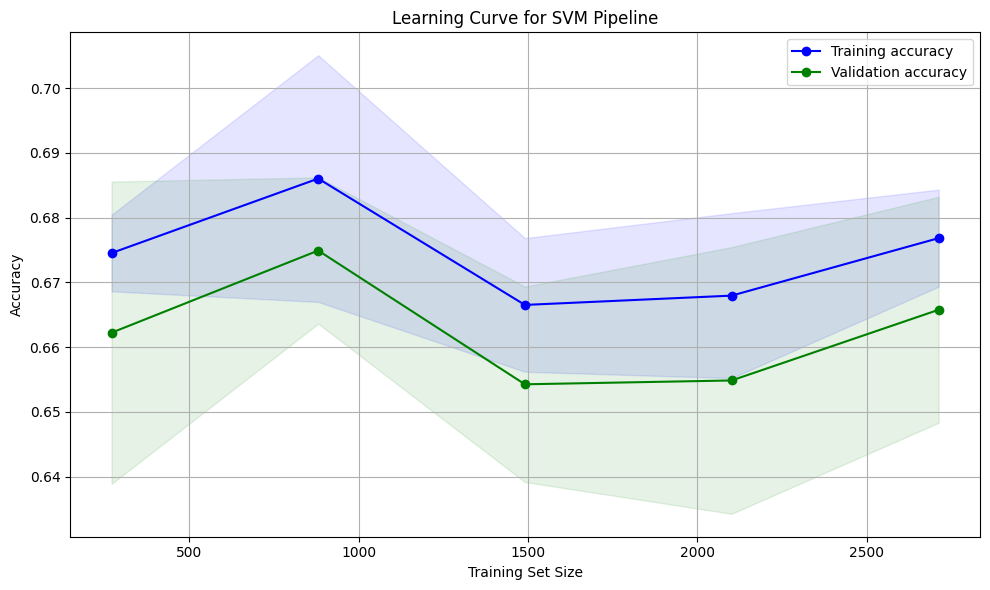

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:   13.1s finished


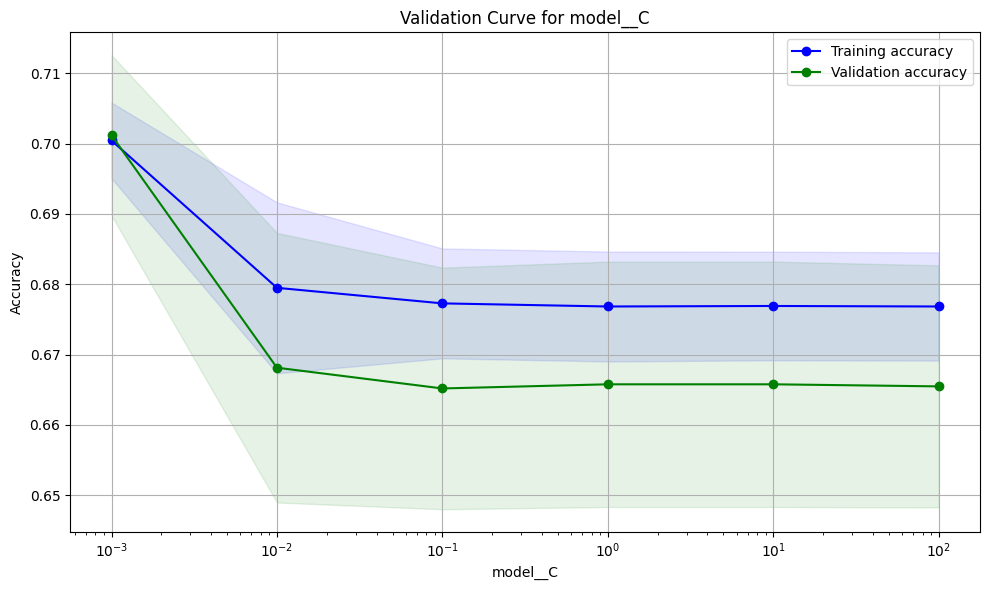

In [14]:
train_file = 'train_standard_scaled.csv'
train_df = load_dataset(os.path.join(DATA_DIR, train_file))
X, y = prepare_features(train_df, FEATURES, TARGET)

# RECREATE the pipeline architecture but unfitted
# Extract pipeline steps but **do not use fitted objects**
# This example assumes your pipeline has 'preprocessor' and 'model' steps

# Extract the preprocessor class and parameters but not fitted transformer objects
preprocessor = model_fitted_pipeline.named_steps['preprocessor']
preprocessor_class = type(preprocessor)

# Create new preprocessor with the same init parameters (if possible)
# This step depends on how you originally created the preprocessor
# Here we try to recreate with the original parameters

# For ColumnTransformer:
if isinstance(preprocessor, ColumnTransformer):
    # Extract transformers spec (names, transformers, columns) without fitted state
    transformers = []
    for name, transformer, cols in preprocessor.transformers:
        # If transformer is 'passthrough' or 'drop', keep as is
        if transformer == 'passthrough' or transformer == 'drop':
            transformers.append((name, transformer, cols))
        else:
            # If transformer is a fitted object (like StandardScaler), recreate unfitted
            transformer_class = type(transformer)
            # Try to instantiate with default constructor; adjust if needed
            new_transformer = transformer_class()
            transformers.append((name, new_transformer, cols))
    new_preprocessor = ColumnTransformer(transformers=transformers)
else:
    raise ValueError("Unexpected preprocessor type. Please adapt the code.")

# Recreate an unfitted SVM with the same parameters as in the fitted model
svm_fitted = model_fitted_pipeline.named_steps['model']
svm_params = svm_fitted.get_params()
svm_unfitted = SVC(**svm_params)

# Rebuild the pipeline
unfitted_pipeline = Pipeline([
    ('preprocessor', new_preprocessor),
    ('model', svm_unfitted)
])

print("Unfitted pipeline recreated.")

# Plot Learning Curve
train_sizes, train_scores, valid_scores = learning_curve(
    unfitted_pipeline, X, y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    verbose=1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
valid_mean = np.mean(valid_scores, axis=1)
valid_std = np.std(valid_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
plt.plot(train_sizes, valid_mean, 'o-', color='green', label='Validation accuracy')
plt.fill_between(train_sizes, valid_mean - valid_std, valid_mean + valid_std, alpha=0.1, color='green')

plt.title('Learning Curve for SVM Pipeline')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'best_model_learning_curve.png'), dpi=300)
plt.show()

# Plot Validation Curve
param_name = 'model__C'
param_range = np.logspace(-3, 2, 6)

train_scores, valid_scores = validation_curve(
    unfitted_pipeline, X, y,
    param_name=param_name,
    param_range=param_range,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
valid_mean = np.mean(valid_scores, axis=1)
valid_std = np.std(valid_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.semilogx(param_range, train_mean, label='Training accuracy', color='blue', marker='o')
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')

plt.semilogx(param_range, valid_mean, label='Validation accuracy', color='green', marker='o')
plt.fill_between(param_range, valid_mean - valid_std, valid_mean + valid_std, alpha=0.1, color='green')

plt.title(f'Validation Curve for {param_name}')
plt.xlabel(param_name)
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'best_model_validation_curve.png'), dpi=300)
plt.show()


<a id='section45'></a>
## 4.5 Feature importance fo best model

```
# Align scikit-learn version to import model
#!{sys.executable} -m pip install scikit-learn==1.6.1
```

Output:
```
Collecting scikit-learn==1.6.1
  Downloading scikit_learn-1.6.1-cp313-cp313-win_amd64.whl.metadata (15 kB)
Requirement already satisfied: numpy>=1.19.5 in c:\users\kety3\appdata\local\programs\python\python313\lib\site-packages (from scikit-learn==1.6.1) (2.2.6)
Requirement already satisfied: scipy>=1.6.0 in c:\users\kety3\appdata\local\programs\python\python313\lib\site-packages (from scikit-learn==1.6.1) (1.16.2)
Requirement already satisfied: joblib>=1.2.0 in c:\users\kety3\appdata\local\programs\python\python313\lib\site-packages (from scikit-learn==1.6.1) (1.5.2)
Requirement already satisfied: threadpoolctl>=3.1.0 in c:\users\kety3\appdata\local\programs\python\python313\lib\site-packages (from scikit-learn==1.6.1) (3.6.0)
Downloading scikit_learn-1.6.1-cp313-cp313-win_amd64.whl (11.1 MB)
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------- ----- 9.4/11.1 MB 66.5 MB/s eta 0:00:01
   ---------------------------------------- 11.1/11.1 MB 59.9 MB/s  0:00:00
Installing collected packages: scikit-learn
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.7.2
    Uninstalling scikit-learn-1.7.2:
      Successfully uninstalled scikit-learn-1.7.2
Successfully installed scikit-learn-1.6.1
```

In [15]:
import sklearn
print(sklearn.__version__)

1.6.1


In [16]:
print(type(model_fitted_pipeline))

<class 'sklearn.pipeline.Pipeline'>


Loaded model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['bmi', 'hypertension',
                                                   'pulse_pressure',
                                                   'cigarettes_per_day',
                                                   'total_cholesterol',
                                                   'glucose', 'heart_rate',
                                                   'age_group_code'])])),
                ('model',
                 SVC(C=5, class_weight='balanced', kernel='linear',
                     probability=True, random_state=42))])
Data shape: (848, 9)


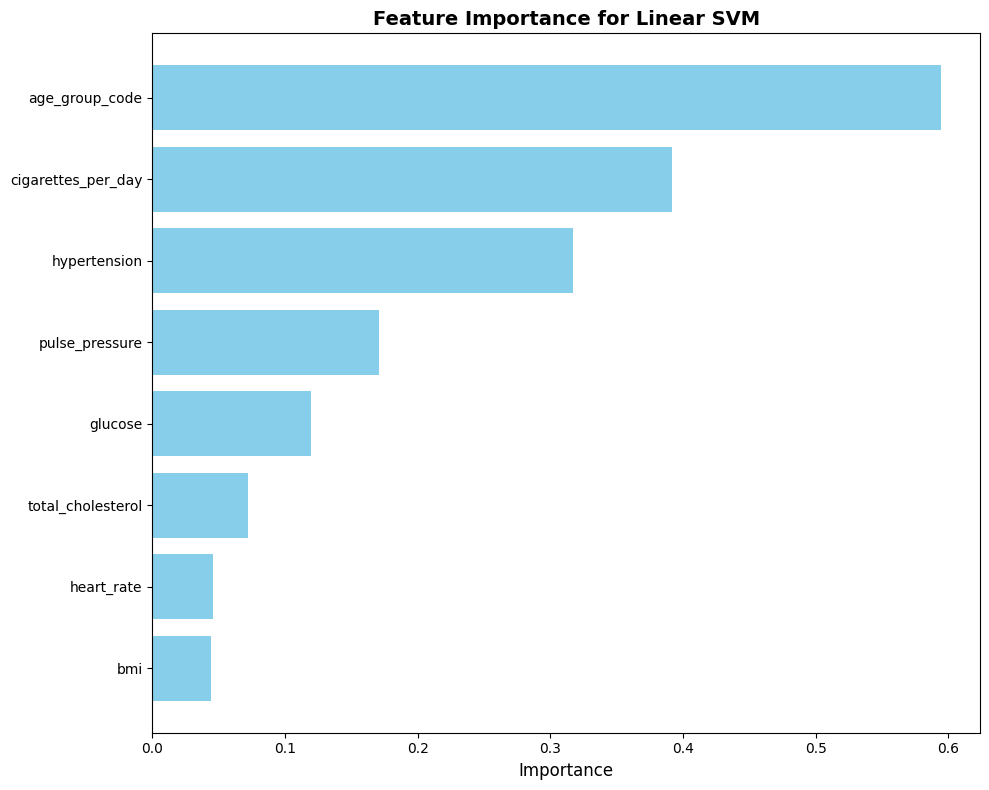

Linear SVM feature importance plotted and saved.


In [17]:
print("Loaded model:", model_fitted_pipeline)

# LOAD DATA
X_scaled = pd.read_csv(os.path.join(DATA_DIR, best_model_dataset_version))
print("Data shape:", X_scaled.shape)

# IDENTIFY SVM INSIDE PIPELINE
svm_model = None

if isinstance(model_fitted_pipeline, SVC):
    svm_model = model_fitted_pipeline
elif isinstance(model_fitted_pipeline, Pipeline):
    for name, step in model_fitted_pipeline.named_steps.items():
        if isinstance(step, SVC):
            svm_model = step
            break

if svm_model is None:
    raise ValueError("No SVM found inside the loaded model!")

# FEATURE IMPORTANCE
if hasattr(svm_model, 'coef_'):
    # LINEAR SVM: Coefficients are used as feature importance
    coef = svm_model.coef_.flatten()
    
    # Get feature names from the preprocessor if using ColumnTransformer
    feature_names = X_scaled.columns.tolist()
    if isinstance(model_fitted_pipeline, Pipeline) and 'preprocessor' in model_fitted_pipeline.named_steps:
        preprocessor = model_fitted_pipeline.named_steps['preprocessor']
        if hasattr(preprocessor, 'transformers_'):
            feature_names = []
            for name, trans, cols in preprocessor.transformers_:
                feature_names.extend(cols)
    
    # Create a DataFrame for plotting
    importance_df = pd.DataFrame({
        'feature': feature_names,
        'importance': np.abs(coef)
    }).sort_values(by='importance', ascending=False)  # Sort descending
    
    # Plot horizontal bar chart
    top_n = len(importance_df)  # or choose a smaller number if desired
    y_pos = np.arange(top_n)
    
    plt.figure(figsize=(10, 8))
    plt.barh(y_pos, importance_df['importance'].head(top_n), color='skyblue')
    plt.yticks(y_pos, importance_df['feature'].head(top_n))
    plt.gca().invert_yaxis()  # Most important feature on top
    plt.title('Feature Importance for Linear SVM', fontsize=14, fontweight='bold')
    plt.xlabel('Importance', fontsize=12)
    plt.tight_layout()

    os.makedirs(SAVE_DIR, exist_ok=True)
    plt.savefig(os.path.join(SAVE_DIR, 'best_model_feature_importance.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Linear SVM feature importance plotted and saved.")
    
else:
    print("This is a non-linear SVM model (e.g., using RBF kernel).")

The feature importance analysis of the Linear SVM model shows that age_group_code is by far the strongest predictor, indicating that age is the most influential factor in distinguishing between healthy and sick patients. Cigarettes per day and hypertension follow, highlighting the strong role of lifestyle-related risk factors and pre-existing conditions in cardiovascular risk. Pulse pressure and glucose contribute moderately, reflecting physiological and metabolic influences. In contrast, total cholesterol, heart rate, and BMI have relatively smaller weights, suggesting a more limited marginal contribution once other variables are accounted for. Overall, the SVM captures clinically meaningful, interpretable risk patterns.

<a id='section46'></a>
## 4.6 SHAP Analysis of best model

In [18]:
# Sample your data (optional but recommended for speed)
X_sample = X_scaled.sample(min(200, len(X_scaled)), random_state=42)

# Extract the linear SVM from the pipeline
svm_model = model_fitted_pipeline.named_steps['model']

# Extract preprocessor
preprocessor = model_fitted_pipeline.named_steps['preprocessor']

# Transform the data using the preprocessor (to get feature space input to the SVM)
X_transformed = preprocessor.transform(X_sample)

# Create the LinearExplainer with the SVM and preprocessed data
explainer = shap.LinearExplainer(svm_model, X_transformed, feature_perturbation="interventional")

# Calculate SHAP values (this is fast for linear models)
shap_values = explainer.shap_values(X_transformed)

# Plot summary plot (use transformed feature names if available)
feature_names = preprocessor.get_feature_names_out()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, features=X_transformed, feature_names=feature_names,show=False)
plt.tight_layout()
save_path = os.path.join(SAVE_DIR, 'best_model_shap_analysis_independent.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.close()

**Comment on the resulting SHAP analysis (independent features):**

The SHAP analysis of the linear SVM model, assuming feature independence, highlights age_group_code as the most influential variable, with higher age groups consistently pushing predictions toward a higher risk of disease. Cigarettes per day also shows a strong positive impact, where increased smoking intensity substantially raises the model output, reinforcing its role as a major modifiable risk factor. Hypertension exhibits a clear directional effect, with hypertensive patients contributing positively to disease prediction. Pulse pressure, total cholesterol, and glucose display moderate but consistent influences, indicating that elevated cardiovascular and metabolic markers increase predicted risk. In contrast, heart rate and BMI show smaller SHAP magnitudes, suggesting limited incremental contribution once other variables are accounted for. Overall, the model captures clinically plausible, interpretable relationships aligned with established cardiovascular risk factors.

In [19]:
# Sample your data (optional but recommended for speed)
X_sample = X_scaled.sample(min(200, len(X_scaled)), random_state=42)

# Extract the linear SVM from the pipeline
svm_model = model_fitted_pipeline.named_steps['model']

# Extract preprocessor
preprocessor = model_fitted_pipeline.named_steps['preprocessor']

# Transform the data using the preprocessor (to get feature space input to the SVM)
X_transformed = preprocessor.transform(X_sample)
feature_names = preprocessor.get_feature_names_out()

# Create the LinearExplainer with the SVM and preprocessed data
plt.figure(figsize=(12, 8))
explainer = shap.LinearExplainer(svm_model, X_transformed, feature_perturbation="correlation_dependent")

# Calculate SHAP values (this is fast for linear models)
shap_values = explainer.shap_values(X_transformed)

# Plot summary plot (use transformed feature names if available)
shap.summary_plot(shap_values, features=X_transformed, feature_names=feature_names, show=False)
plt.tight_layout()
save_path = os.path.join(SAVE_DIR, 'best_model_shap_analysis_correlated.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.close()

Estimating transforms:   0%|          | 0/1000 [00:00<?, ?it/s]

**Comment on the resulting SHAP analysis (correlated features):**

When accounting for feature correlation, the SHAP analysis of the linear SVM model shows a clearer and more structured separation of feature effects. **Age group** remains the dominant predictor, with higher values strongly pushing predictions toward higher cardiovascular risk. **Hypertension** exhibits a pronounced positive impact, reflecting its strong association with disease when shared variance with other clinical variables is considered. **Pulse pressure** and **cigarettes per day** show wider SHAP value distributions, indicating heterogeneous effects across patients and potential interactions with age and blood pressure. **Total cholesterol**, **BMI**, and **glucose** contribute moderately, with higher values generally increasing predicted risk. **Heart rate** remains the least influential feature, with SHAP values tightly clustered around zero. Overall, considering correlated features yields more realistic attribution patterns, improving clinical interpretability by reducing redundant importance across related risk factors.
